In [1]:
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
import numpy as np
import random

In [2]:
from keras import models,layers
from keras.layers import BatchNormalization, Dropout
from keras.callbacks import EarlyStopping
from keras.optimizers import Adam

In [3]:
x_train = np.load('mnist.npz/x_train.npy')
y_train = np.load('mnist.npz/y_train.npy')
x_test  = np.load('mnist.npz/x_test.npy')
y_test  = np.load('mnist.npz/y_test.npy')

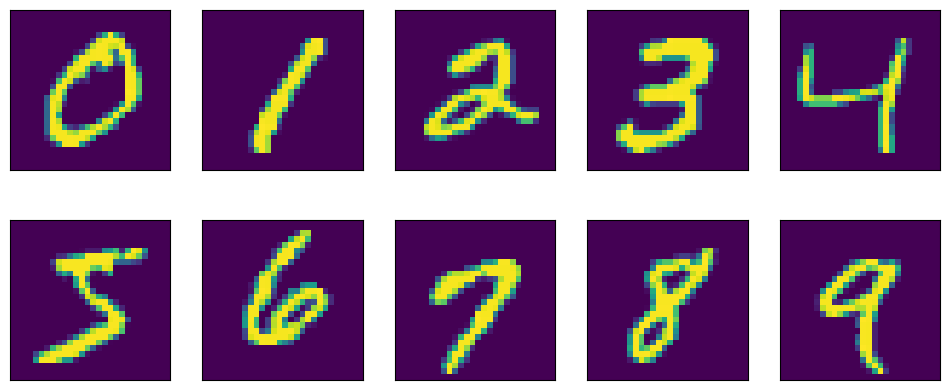

In [4]:
unique_labels = np.unique(y_train)
plt.figure(figsize=(12, 5))
for i in range(len(unique_labels)):
    idx = np.where(y_train == unique_labels[i])[0][0]
    plt.subplot(2, 5, i+1)
    plt.imshow(x_train[idx])
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
plt.show()

In [5]:
max_pixel_val = x_train.max()
x_train = x_train.astype('float32') / max_pixel_val
x_test  = x_test.astype('float32') / max_pixel_val

In [7]:
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28,28,1)),
    BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    Dropout(0.25),
    layers.Conv2D(64, (3, 3), activation='relu'),
    BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    Dropout(0.25),
    layers.Conv2D(64, (3, 3), activation='relu'),
    BatchNormalization(),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)                    │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 26, 26, 32)          │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_4                │ (None, 11, 11, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 3, 3, 64)            │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_5                │ (None, 3, 3, 64)            │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 576)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 64)                  │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 93,962 (367.04 KB)

 Trainable params: 93,642 (365.79 KB)

 Non-trainable params: 320 (1.25 KB)

In [8]:
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stop = EarlyStopping(monitor='val_loss',patience=7,restore_best_weights=True)
history = model.fit(
    x_train, y_train,
    epochs=50,
    validation_data=(x_test, y_test),
    callbacks=[early_stop],
    batch_size=64,
    verbose=1
)

Epoch 1/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 62s 61ms/step - accuracy: 0.9536 - loss: 0.1474 - val_accuracy: 0.9826 - val_loss: 0.0540
Epoch 2/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 82s 61ms/step - accuracy: 0.9838 - loss: 0.0529 - val_accuracy: 0.9888 - val_loss: 0.0346
Epoch 3/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 82s 60ms/step - accuracy: 0.9872 - loss: 0.0394 - val_accuracy: 0.9898 - val_loss: 0.0322
Epoch 4/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 80s 58ms/step - accuracy: 0.9889 - loss: 0.0341 - val_accuracy: 0.9874 - val_loss: 0.0411
Epoch 5/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 57s 61ms/step - accuracy: 0.9906 - loss: 0.0282 - val_accuracy: 0.9914 - val_loss: 0.0302
Epoch 6/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 80s 59ms/step - accuracy: 0.9914 - loss: 0.0263 - val_accuracy: 0.9915 - val_loss: 0.0269
Epoch 7/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 84s 61ms/step - accuracy: 0.9928 - loss: 0.0218 - val_accuracy: 0.9905 - val_loss: 0.0323
Epoch 8/50
938/938 ━━━━━━━━━━━━━━━━━━━━ 80s 58ms/step - accuracy: 0.9933 - loss: 0.0205 - 

In [9]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.9924 - loss: 0.0245


313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step
Predicted: 3
Actual: 3


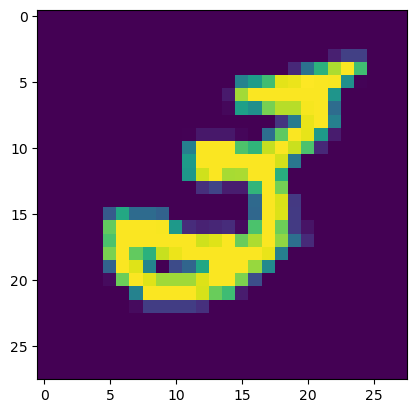

In [11]:
n = random.randint(0, len(x_test)-1)
predicted_values = model.predict(x_test)
predicted_class = np.argmax(predicted_values[n])
actual_class=y_test[n]
plt.imshow(x_test[n])
print(f"Predicted: {predicted_class}\nActual: {actual_class}")

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'], marker='o')
plt.plot(history.history['val_accuracy'], marker='s')
plt.title('MODEL ACCURACY', fontsize=16, fontweight='bold')
plt.ylabel('Accuracy', fontsize=12)
plt.xlabel('Epoch', fontsize=12)
plt.legend(['Train', 'Validation'], loc='lower right')
plt.grid(True)
plt.show()